In [1]:
from pathlib import Path
from sklearn.model_selection import train_test_split
import pandas as pd
random_state = 42
DATA_PATH = (
    Path.cwd().parent
    / "data"
    / "ai4i2020.csv"
)
df  = pd.read_csv(DATA_PATH)
print("df.shape():", df.shape)
print("Column names:", df.columns.tolist())


df.shape(): (10000, 14)
Column names: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [3]:
target = "Machine failure"
excluded_columns = [
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]
x = df.drop(columns=excluded_columns)
y = df[target].astype(int)
print("Features: ",x.shape)
print("Target: ",y.shape)
print("\nTarget distribution:\n", y.value_counts(normalize=True))


Features:  (10000, 6)
Target:  (10000,)

Target distribution:
 Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64


In [5]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# First, set aside 30% for validation and final testing
X_train, X_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split the remaining 30% equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nFailure counts:")
print("Train:", y_train.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict())
print("Test:", y_test.value_counts().to_dict())

Training: (7000, 6) (7000,)
Validation: (1500, 6) (1500,)
Testing: (1500, 6) (1500,)

Failure counts:
Train: {0: 6763, 1: 237}
Validation: {0: 1449, 1: 51}
Test: {0: 1449, 1: 51}


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Identify feature types using training data only
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


C:\Users\kumar\AppData\Local\Temp\ipykernel_59508\2494568509.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [7]:
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train using only the training set
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [8]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Predictions
y_val_pred = baseline_model.predict(X_val)
y_val_prob = baseline_model.predict_proba(X_val)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, y_val_prob), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, y_val_prob), 4))

Confusion Matrix:
[[1215  234]
 [  14   37]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.84      0.91      1449
     Failure       0.14      0.73      0.23        51

    accuracy                           0.83      1500
   macro avg       0.56      0.78      0.57      1500
weighted avg       0.96      0.83      0.88      1500

PR-AUC (Average Precision): 0.3829
ROC-AUC: 0.875


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using training data only
rf_model.fit(X_train, y_train)

# Evaluate on validation data
y_val_pred_rf = rf_model.predict(X_val)
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_val, y_val_prob_rf), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val, y_val_prob_rf), 4
))

Confusion Matrix:
[[1434   15]
 [  22   29]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      0.99      0.99      1449
     Failure       0.66      0.57      0.61        51

    accuracy                           0.98      1500
   macro avg       0.82      0.78      0.80      1500
weighted avg       0.97      0.98      0.97      1500

PR-AUC: 0.677
ROC-AUC: 0.9696


In [10]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Calculate class imbalance using training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train
xgb_model.fit(X_train, y_train)

# Validate
y_val_pred_xgb = xgb_model.predict(X_val)
y_val_prob_xgb = xgb_model.predict_proba(X_val)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_xgb,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_val, y_val_prob_xgb), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val, y_val_prob_xgb), 4
))

Confusion Matrix:
[[1415   34]
 [  10   41]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.98      1449
     Failure       0.55      0.80      0.65        51

    accuracy                           0.97      1500
   macro avg       0.77      0.89      0.82      1500
weighted avg       0.98      0.97      0.97      1500

PR-AUC: 0.6844
ROC-AUC: 0.98


In [11]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

models = {
    "Logistic Regression": baseline_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

rows = []

for name, model in models.items():
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    rows.append({
        "Model": name,
        "Failure Precision": precision_score(y_val, pred, zero_division=0),
        "Failure Recall": recall_score(y_val, pred, zero_division=0),
        "Failure F1": f1_score(y_val, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_val, prob),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

validation_results = pd.DataFrame(rows)
validation_results = validation_results.sort_values(
    by="PR-AUC", ascending=False
)

display(validation_results.round(4))

,Model,Failure Precision,Failure Recall,Failure F1,PR-AUC,ROC-AUC
2,XGBoost,0.5467,0.8039,0.6508,0.6844,0.9800
1,Random Forest,0.6591,0.5686,0.6105,0.6770,0.9696
0,Logistic Regression,0.1365,0.7255,0.2298,0.3829,0.8750


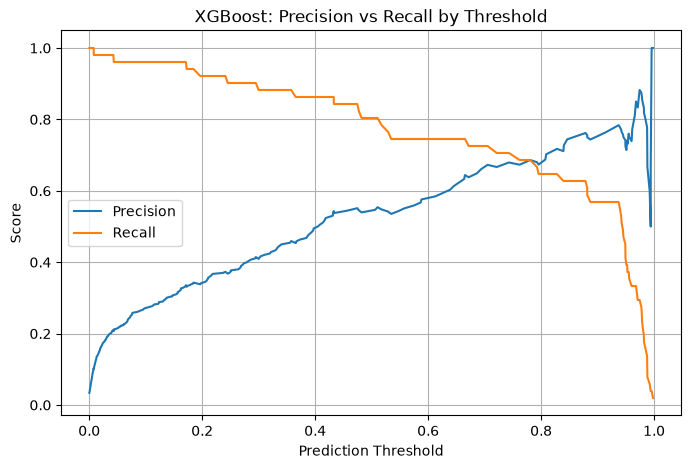

In [12]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob_xgb
)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.title("XGBoost: Precision vs Recall by Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

thresholds_to_test = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

rows = []

for threshold in thresholds_to_test:
    y_pred = (y_val_prob_xgb >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "False Alarms": fp,
        "Missed Failures": fn,
        "Detected Failures": tp
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(4))

,Threshold,Precision,Recall,F1,False Alarms,Missed Failures,Detected Failures
0,0.30,0.4091,0.8824,0.5590,65,6,45
1,0.35,0.4545,0.8824,0.6000,54,6,45
2,0.40,0.5000,0.8627,0.6331,44,7,44
3,0.45,0.5443,0.8431,0.6615,36,8,43
4,0.50,0.5467,0.8039,0.6508,34,10,41
5,0.55,0.5507,0.7451,0.6333,31,13,38
6,0.60,0.5846,0.7451,0.6552,27,13,38


In [14]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Predict failure probabilities on the untouched test set
y_test_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
chosen_threshold = 0.40
y_test_pred_xgb = (
    y_test_prob_xgb >= chosen_threshold
).astype(int)

print("Chosen Threshold:", chosen_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_xgb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_xgb,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_test, y_test_prob_xgb), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_test_prob_xgb), 4)
)

Chosen Threshold: 0.4

Confusion Matrix:
[[1394   55]
 [   8   43]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.96      0.98      1449
     Failure       0.44      0.84      0.58        51

    accuracy                           0.96      1500
   macro avg       0.72      0.90      0.78      1500
weighted avg       0.98      0.96      0.96      1500

PR-AUC: 0.76
ROC-AUC: 0.9681


In [15]:
from pathlib import Path
import joblib

# Create the models directory at the project root
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save model and selected threshold together
artifact = {
    "model": xgb_model,
    "threshold": 0.40,
    "model_name": "XGBoost",
    "target": "Machine failure",
    "features": X_train.columns.tolist()
}

model_path = models_dir / "machinewhisperer_model.joblib"

joblib.dump(artifact, model_path)

print("Model saved successfully!")
print("Path:", model_path.resolve())

Model saved successfully!
Path: C:\Users\kumar\OneDrive\Desktop\MachineWhisperer\models\machinewhisperer_model.joblib
